# F4, F5, F6, F8: occupations, k-point weights, spectrum normalization (F4, F5 implemented; F6, F8 upcoming)

| finding | what | checked here with |
|---|---|---|
| F4 | `fillings` dump is ×2 for `spintype no-spin`, while computed occupations are in [0,1] | `N2_nospin` (legacy vs. fixed) and the z-spin N2 pair |
| F5 | symmetry-reduced meshes average single atoms/bonds/m-orbitals; `get_wk_t` dropped symmetry weights | `graphene_zspin_full` vs. `graphene_zspin_symm` |
| F6 | Gaussian kernel unnormalized; LTI applies 1/N_k twice | N2 DOS, and a synthetic dispersive band through `get_lti_spectrum` |
| F8 | `calculate_filling_nobroad` inverted; Gauss/MP1/cold helpers crash on arrays | the helpers vs. JDFTx's `ElecInfo::smear` |

Each section detects whether its fix has landed, from the legacy switch (F4–F6) or from behaviour (F8). Known-bug
checks document the current state and stop being reached once the fix lands.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs.general import SIGMA_DEFAULT
from scipy.special import erfc
from scipy.integrate import trapezoid
from crawfish.funcs import get_dos
from crawfish.core.operations.vector import get_lti_spectrum
from crawfish.io.data_parsing import get_wk_t
from crawfish.core import elecdata as ed_mod
from crawfish.utils.testing import EXAMPLE_CALC_DIRS_DIR

print({f: fix_available(f) for f in ["F4", "F5", "F6"]})

{'F4': True, 'F5': True, 'F6': False}


## F6: spectrum normalization

The integral of the total DOS over all energies should be $\sum_t w_t \cdot n_\text{bands}$, the number of states
(30 here). The reference normalizes crawfish's Gaussian by $1/\sqrt{\pi\,\sigma}$.

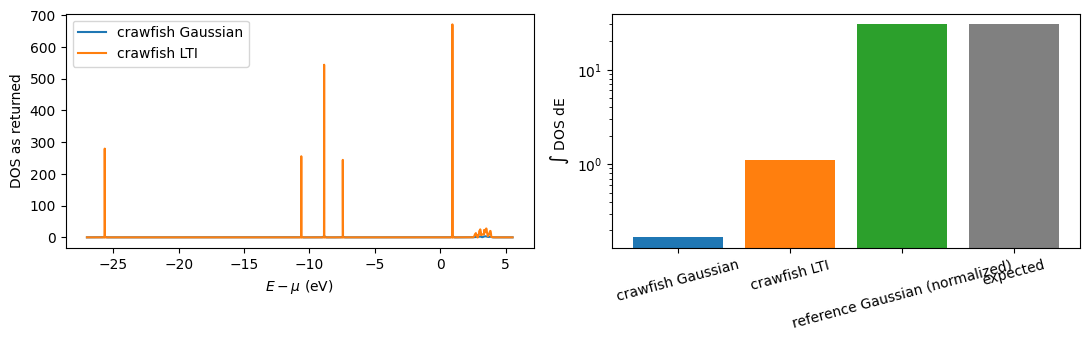

crawfish Gaussian                   0.1681
crawfish LTI                        1.1079
reference Gaussian (normalized)    30.0000
expected                           30.0000
dtype: float64

In [2]:
edata = load_edata()
SIG = SIGMA_DEFAULT
erange = np.arange(edata.e_tj.min() - 0.05, edata.e_tj.max() + 0.05, 0.0002, dtype=np.float32)
expected = float(edata.wk_t.sum() * edata.nbands)
_, dos_g = get_dos(edata, erange=erange, sig=SIG)
_, dos_l = get_dos(edata, erange=erange, lti=True, rattle_eigenvals=True)
dos_g_ref = np.asarray(dos_g) / np.sqrt(np.pi * SIG)
integrals = {"crawfish Gaussian": trapezoid(dos_g, erange), "crawfish LTI": trapezoid(dos_l, erange),
             "reference Gaussian (normalized)": trapezoid(dos_g_ref, erange), "expected": expected}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
x = to_ev_rel_mu(edata, erange)
axes[0].plot(x, dos_g, label="crawfish Gaussian")
axes[0].plot(x, dos_l, label="crawfish LTI")
axes[0].set_ylabel("DOS as returned")
axes[0].set_xlabel(r"$E - \mu$ (eV)")
axes[0].legend()
axes[1].bar(list(integrals), list(integrals.values()), color=["C0", "C1", "C2", "gray"])
axes[1].set_yscale("log")
axes[1].set_ylabel(r"$\int$ DOS dE")
axes[1].tick_params(axis="x", labelrotation=15)
fig.tight_layout()
savefig(fig, "F6_dos_normalization_n2")
plt.show()
pd.Series(integrals).round(4)

N2's bands are flat (an isolated molecule), which LTI resolves poorly. The LTI double counting is clearer on a
dispersive band, so a cosine band on a 6×6×6 grid goes straight through crawfish's `get_lti_spectrum`. With
k-weighted input (what crawfish passes today) the integral is 1/N_k per band instead of 1.

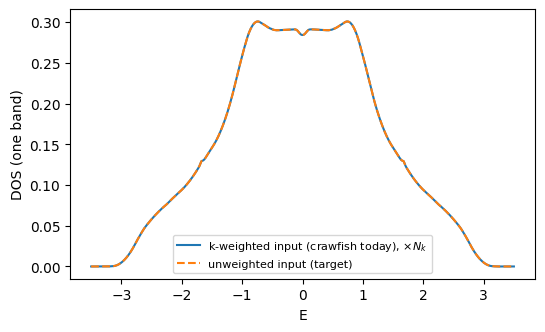

{'k-weighted': np.float32(0.0046296306), 'unweighted': np.float32(1.0000002)}

In [3]:
ng = 6
k = np.stack(np.meshgrid(*[np.arange(ng) / ng] * 3, indexing="ij"), -1)
eig = (np.cos(2 * np.pi * k[..., 0]) + np.cos(2 * np.pi * k[..., 1]) + np.cos(2 * np.pi * k[..., 2]))
e_sabcj = eig[None, ..., None].astype(np.float32)
e0 = np.linspace(-3.5, 3.5, 1401, dtype=np.float32)
w_k = np.full(e_sabcj.shape, 1 / ng**3, dtype=np.float32)  # k-weights for one spin channel
lti_kweighted = np.asarray(get_lti_spectrum(e_sabcj, e0, w_k, np.eye(3))[0])
lti_unweighted = np.asarray(get_lti_spectrum(e_sabcj, e0, np.ones_like(w_k), np.eye(3))[0])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(e0, lti_kweighted * ng**3, label=r"k-weighted input (crawfish today), $\times N_k$")
ax.plot(e0, lti_unweighted, "--", label="unweighted input (target)")
ax.set_xlabel("E")
ax.set_ylabel("DOS (one band)")
ax.legend(fontsize=8)
savefig(fig, "F6_lti_double_counting")
plt.show()
lti_integrals = {"k-weighted": trapezoid(lti_kweighted, e0), "unweighted": trapezoid(lti_unweighted, e0)}
lti_integrals

## F8: occupation helpers vs. JDFTx's `ElecInfo::smear`

JDFTx uses $x = (\varepsilon-\mu)/(2\sigma)$. The Fermi function is $\tfrac12(1-\tanh x)$ and the Gaussian
filling is $\tfrac12\operatorname{erfc} x$; MP1 and Cold smearing are defined in the same source. The crawfish
helpers are called on an array, as `ElecData.occ_tj` does. When a helper raises, the reference curve is still
drawn.

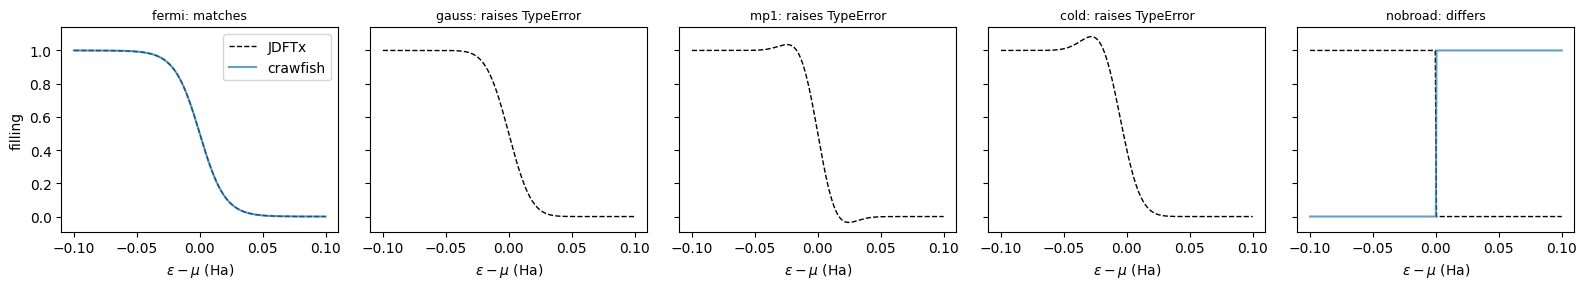

{'fermi': 'matches',
 'gauss': 'raises TypeError',
 'mp1': 'raises TypeError',
 'cold': 'raises TypeError',
 'nobroad': 'differs'}

In [4]:
mu, sigma = 0.0, 0.01
eps = np.linspace(-0.1, 0.1, 401)
xx = (eps - mu) / (2 * sigma)
jdftx = {
    "fermi": 0.5 * (1 - np.tanh(xx)),
    "gauss": 0.5 * erfc(xx),
    "mp1": 0.5 * erfc(xx) - xx * np.exp(-xx**2) / (2 * np.sqrt(np.pi)),
    "cold": 0.5 * erfc(xx + np.sqrt(0.5)) + np.exp(-(xx + np.sqrt(0.5)) ** 2) / np.sqrt(2 * np.pi),
    "nobroad": np.heaviside(mu - eps, 0.5),
}
status = {}
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, (name, ref_f) in zip(axes, jdftx.items()):
    ax.plot(eps, ref_f, "k--", lw=1, label="JDFTx")
    try:
        got = getattr(ed_mod, f"calculate_filling_{name}")(sigma, eps, mu)
        ax.plot(eps, got, alpha=0.7, label="crawfish")
        status[name] = "matches" if np.allclose(got, ref_f, atol=1e-8) else "differs"
    except Exception as err:
        status[name] = f"raises {type(err).__name__}"
    ax.set_title(f"{name}: {status[name]}", fontsize=9)
    ax.set_xlabel(r"$\varepsilon - \mu$ (Ha)")
axes[0].set_ylabel("filling")
axes[0].legend()
fig.tight_layout()
savefig(fig, "F8_filling_helpers")
plt.show()
status

## F4: fillings files for spin-unpolarized calculations (implemented)

**Finding:** JDFTx's `Dump.cpp` writes `fillings` as 2 × its internal [0, 1] fillings for `spintype no-spin`, and
its k-point weights already sum to 2. Read as-is, the file double-counts electrons. **Fix:** `ElecData.occ_tj`
divides the file by `spin_weight`, and integrated spectra no longer divide occupations by their maximum (that
rescaling hid the factor 2 for integrated spectra, but not for the density matrix behind pCOBI). **Legacy
switch:** `legacy_fillings=True`.

`N2_nospin` is a gas-phase N2 calculation run locally for this (same geometry as `N2_bare_min`, no-spin, 2×2×2).
`N2_bare_min` and `N2_no_fillings` are the same z-spin calculation with and without a `fillings` file. z-spin
fillings aren't doubled, so they check that the fix leaves spin-polarized data alone.

raw no-spin fillings file: max 2.0


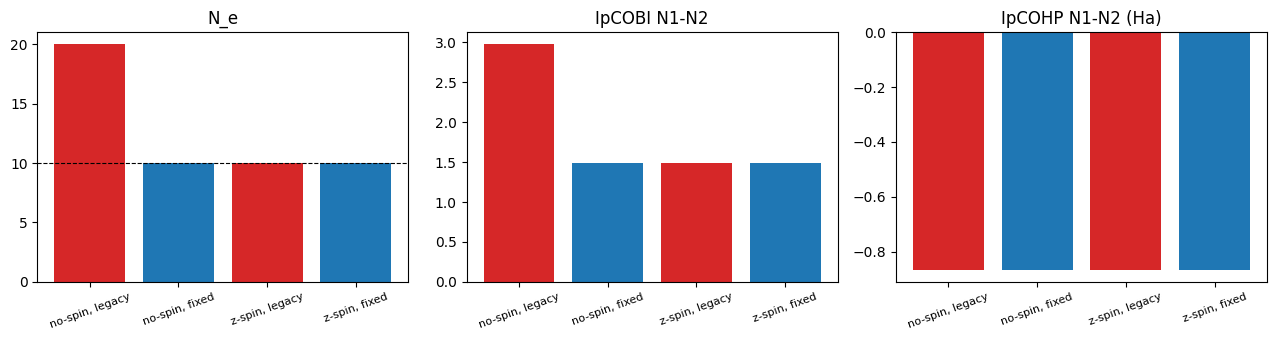

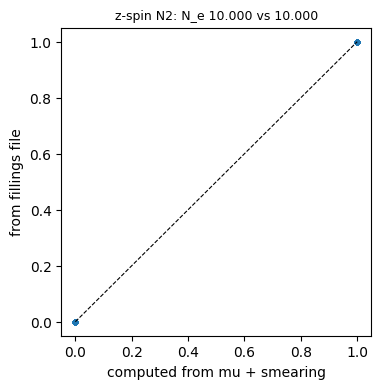

,N_e,N_e (outfile),max occupation,IpCOBI N1-N2,IpCOHP N1-N2 (Ha)
"no-spin, legacy",20.0,10.0,2.0,2.97762,-0.86680
"no-spin, fixed",10.0,10.0,1.0,1.48881,-0.86680
"z-spin, legacy",10.0,10.0,1.0,1.49349,-0.86678
"z-spin, fixed",10.0,10.0,1.0,1.49349,-0.86678


In [5]:
from crawfish.funcs import get_ipcobi, get_ipcohp

ne = lambda ed: float(np.sum(ed.wk_t[:, None].astype(np.float64) * ed.occ_tj))
last = lambda func, ed: last_value(func(ed, idcs1=0, idcs2=1, use_cache=False))
print("raw no-spin fillings file: max", np.fromfile(N2_NOSPIN_CALC_DIR / "fillings").max())

versions = {
    "no-spin, legacy": load_edata_at("F4", fixed=False, calc_dir=N2_NOSPIN_CALC_DIR),
    "no-spin, fixed": load_edata_at("F4", fixed=True, calc_dir=N2_NOSPIN_CALC_DIR),
    "z-spin, legacy": load_edata_at("F4", fixed=False),
    "z-spin, fixed": load_edata_at("F4", fixed=True),
}
f4_table = pd.DataFrame({
    name: {"N_e": ne(ed), "N_e (outfile)": ed.outfile.total_electrons, "max occupation": float(ed.occ_tj.max()),
           "IpCOBI N1-N2": last(get_ipcobi, ed), "IpCOHP N1-N2 (Ha)": last(get_ipcohp, ed)}
    for name, ed in versions.items()
}).T

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
colors = ["C3", "C0", "C3", "C0"]
for ax, col in zip(axes, ["N_e", "IpCOBI N1-N2", "IpCOHP N1-N2 (Ha)"]):
    ax.bar(range(len(f4_table)), f4_table[col], color=colors)
    ax.set_xticks(range(len(f4_table)), f4_table.index, rotation=20, fontsize=8)
    ax.set_title(col)
axes[0].axhline(10, color="k", ls="--", lw=0.8)
fig.tight_layout()
savefig(fig, "F4_nospin_fillings")
plt.show()

with_file, without_file = load_edata(), load_edata(Path(EXAMPLE_CALC_DIRS_DIR) / "N2_no_fillings")
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(without_file.occ_tj.ravel(), with_file.occ_tj.ravel(), s=8)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("computed from mu + smearing")
ax.set_ylabel("from fillings file")
ax.set_title(f"z-spin N2: N_e {ne(with_file):.3f} vs {ne(without_file):.3f}", fontsize=9)
savefig(fig, "F4_occupations_zspin")
plt.show()
f4_table.round(5)

## F5: symmetry-reduced k-meshes (implemented)

**Finding:** with JDFTx's default `symmetries automatic`, only the irreducible k-points are computed. Each one
stands in for its symmetry-equivalent k-points, which belong to other, equivalent atoms, bonds and m-orbitals.
Quantities for one atom, bond or m-orbital are then averaged over their equivalent copies. Only selections the
point group maps onto themselves come out exact: the sum over all lattice images, complete orbital shells and
complete sets of equivalent atoms. Separately, `get_wk_t` discarded JDFTx's symmetry weights for spin-polarized
reduced meshes.

**Fix:**
- JDFTx's weights are used. If `kPts` is missing, they come from the `bandProjections` header.
- Single-image pair spectra (including R = 0) raise on a reduced mesh.
- `image="all"` pair spectra and atom/orbital-subset pDOS warn.

**Legacy switch:** `legacy_reduced_kmesh=True`.

**Time-reversal unfolding (default, `ElecData.unfold_time_reversal`):** a mesh reduced only by k ↔ −k is unfolded
onto the full mesh exactly, using T(−k) = T(k)* for collinear calculations. JDFTx produces such a mesh with
`symmetries manual` and only the identity matrix, at about half the cost of `symmetries none`.

`graphene_zspin_full`, `graphene_zspin_symm` and `graphene_zspin_tr` are the same z-spin graphene calculation
(12×12×1 mesh, 20 bands), run with `symmetries none` (144 k per spin), `symmetries automatic` (19 k per spin) and
identity-only `symmetries manual` (74 k per spin, unfolded to 144).

time-reversal run unfolded: True (148 computed states -> 288)


/Users/richb/vs/crawfish/src/crawfish/core/elecdata.py:1231: UserWarning: WARNING: Internal inconsistency found with respect to input parameters (nSpin * nk-pts != nStates).
  self._lti_allowed = _get_lti_allowed(self.bandfile_header_filepath, self.outfile_filepath)
/Users/richb/vs/crawfish/src/crawfish/core/elecdata.py:1137: UserWarning: Kpts file does not match expected number of k-points. k-point weights will be meaningless.
  self._wk_t = get_wk_t(


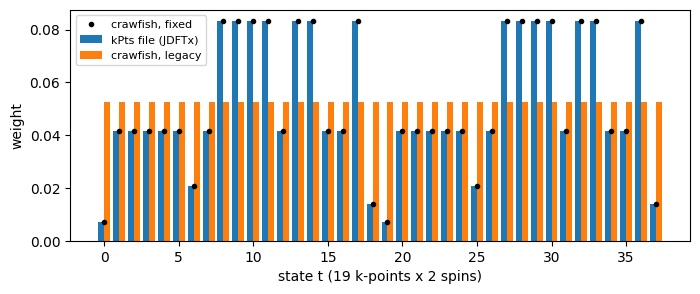

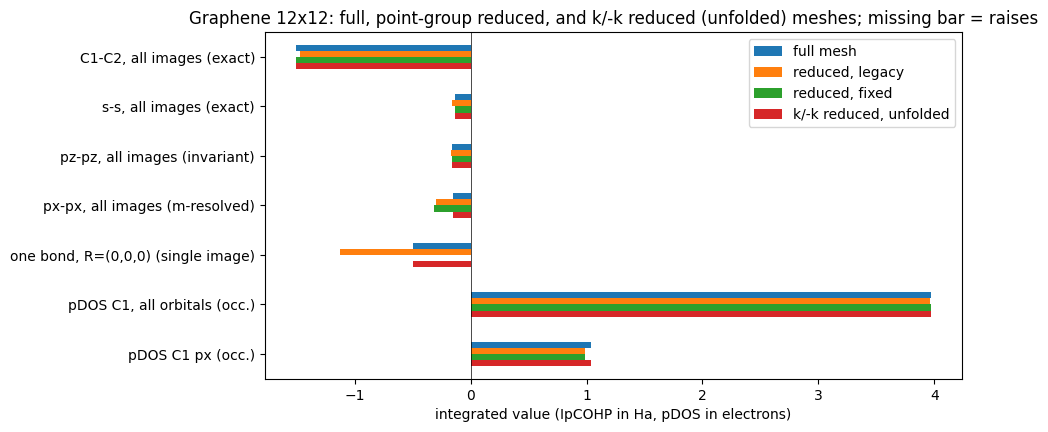

get_ipcohp(reduced mesh, default image='nearest') raises:
  pCOHP for a single lattice image (image='nearest') can't be recovered from a k-mesh reduced by symmetry: every k-point stands in for its symmetry-equivalent ones, which belong to other, equivalent bonds. Use image='all' (exact when summed over symmetry-equivalent atoms and complete orbital shells). Rerun JDFTx with 'symmetries none' for atom-, bond- or orbital-resolved results (notes/theory_audit.md, F5).


,full mesh,"reduced, legacy","reduced, fixed","k/-k reduced, unfolded"
"C1-C2, all images (exact)",-1.50268,-1.47588,-1.50264,-1.50265
"s-s, all images (exact)",-0.13667,-0.16354,-0.13667,-0.13667
"pz-pz, all images (invariant)",-0.16319,-0.16941,-0.16319,-0.16319
"px-px, all images (m-resolved)",-0.14881,-0.30163,-0.31527,-0.14880
"one bond, R=(0,0,0) (single image)",-0.50127,-1.12406,NaN,-0.50126
"pDOS C1, all orbitals (occ.)",3.96690,3.96426,3.96681,3.96680
pDOS C1 px (occ.),1.03893,0.99023,0.98570,1.03889


In [6]:
import warnings
from crawfish.funcs.pcohp import _get_pcohp_tj
from crawfish.funcs.dos import get_pdos_tj
from crawfish.utils.indexing import get_orb_idcs
from crawfish.io.data_parsing import parse_kptsfile

GR_FULL = Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_full"
GR_SYMM = Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_symm"
GR_TR = Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_tr"
gr = {
    "full mesh": load_edata_at("F5", fixed=True, calc_dir=GR_FULL),
    "reduced, legacy": load_edata_at("F5", fixed=False, calc_dir=GR_SYMM),
    "reduced, fixed": load_edata_at("F5", fixed=True, calc_dir=GR_SYMM),
    "k/-k reduced, unfolded": load_edata_at("F5", fixed=True, calc_dir=GR_TR),
}
print("time-reversal run unfolded:", gr["k/-k reduced, unfolded"].time_reversal_unfolded,
      f"({gr['k/-k reduced, unfolded'].nstates_file} computed states -> {gr['k/-k reduced, unfolded'].nstates})")

def icohp(ed, image, o=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(np.sum(ed.occ_tj * _get_pcohp_tj(ed, 0, None, o, 1, None, o, use_cache=False, image=image)))

def occ_pdos(ed, idcs, orbs):
    return float(np.sum(ed.occ_tj * get_pdos_tj(ed.proj_tju, get_orb_idcs(ed, idcs, None, orbs), ed.wk_t)))

# The weights themselves
file_w = np.array(parse_kptsfile(GR_SYMM / "kPts")[0])
fig, ax = plt.subplots(figsize=(8, 3))
idx = np.arange(len(file_w))
ax.bar(idx - 0.2, file_w, 0.4, label="kPts file (JDFTx)")
ax.bar(idx + 0.2, gr["reduced, legacy"].wk_t, 0.4, label="crawfish, legacy")
ax.plot(idx, gr["reduced, fixed"].wk_t, "k.", label="crawfish, fixed")
ax.set_xlabel("state t (19 k-points x 2 spins)")
ax.set_ylabel("weight")
ax.legend(fontsize=8)
savefig(fig, "F5_reduced_mesh_weights")
plt.show()

# What survives the reduction. "full mesh" is the reference; legacy runs unguarded with uniform weights
rows = {
    "C1-C2, all images (exact)": lambda ed: icohp(ed, "all"),
    "s-s, all images (exact)": lambda ed: icohp(ed, "all", "s"),
    "pz-pz, all images (invariant)": lambda ed: icohp(ed, "all", "pz"),
    "px-px, all images (m-resolved)": lambda ed: icohp(ed, "all", "px"),
    "one bond, R=(0,0,0) (single image)": lambda ed: icohp(ed, [0, 0, 0]),
    "pDOS C1, all orbitals (occ.)": lambda ed: occ_pdos(ed, 0, None),
    "pDOS C1 px (occ.)": lambda ed: occ_pdos(ed, 0, "px"),
}
f5_table = pd.DataFrame({name: {row: func(ed) for row, func in rows.items()}
                         for name, ed in [("full mesh", gr["full mesh"]), ("reduced, legacy", gr["reduced, legacy"])]})
# Fixed crawfish: same numbers where exact, but single images raise
fixed_vals = {}
for row, func in rows.items():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fixed_vals[row] = func(gr["reduced, fixed"])
    except ValueError:
        fixed_vals[row] = np.nan  # raised
f5_table["reduced, fixed"] = pd.Series(fixed_vals)
f5_table["k/-k reduced, unfolded"] = pd.Series({row: func(gr["k/-k reduced, unfolded"]) for row, func in rows.items()})

ax = f5_table.plot.barh(figsize=(9, 4.5))
ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("integrated value (IpCOHP in Ha, pDOS in electrons)")
ax.set_title("Graphene 12x12: full, point-group reduced, and k/-k reduced (unfolded) meshes; missing bar = raises")
ax.invert_yaxis()
savefig(ax.figure, "F5_reduced_mesh_quantities")
plt.show()

try:
    from crawfish.funcs import get_ipcohp
    get_ipcohp(gr["reduced, fixed"], idcs1=0, idcs2=1)
except ValueError as err:
    print("get_ipcohp(reduced mesh, default image='nearest') raises:\n ", err)
f5_table.round(5)

## Tests

In [7]:
# F6
if fix_available("F6"):
    assert np.isclose(integrals["crawfish Gaussian"], expected, rtol=0.01)
    # The LTI fix may live in the callers rather than get_lti_spectrum; check the N2 DOS integral by eye
    print("LTI DOS integral after F6:", integrals["crawfish LTI"], "expected", expected, "(flat bands: approximate)")
else:
    assert np.isclose(integrals["reference Gaussian (normalized)"], expected, rtol=0.01)
    assert np.isclose(lti_integrals["unweighted"], 1.0, rtol=0.01)
    assert np.isclose(lti_integrals["k-weighted"], 1 / ng**3, rtol=0.01)  # known bug: extra 1/N_k
    assert not np.isclose(integrals["crawfish Gaussian"], expected, rtol=0.5)  # known bug: unnormalized

# F8: behaviour-based (no legacy switch)
assert status["fermi"] == "matches"
if all(status[n] == "matches" for n in jdftx):
    print("F8 fixed: all helpers match JDFTx.")
else:
    assert status["nobroad"] == "differs" and status["gauss"].startswith("raises"), status  # known bugs

# F4: no-spin fillings halved (legacy double-counts), z-spin untouched, file and computed occupations agree
assert fix_available("F4")
assert np.isclose(f4_table.loc["no-spin, fixed", "N_e"], 10, atol=1e-3)
assert np.isclose(f4_table.loc["no-spin, legacy", "N_e"], 20, atol=1e-3)
assert np.isclose(f4_table.loc["no-spin, legacy", "IpCOBI N1-N2"], 2 * f4_table.loc["no-spin, fixed", "IpCOBI N1-N2"], rtol=1e-5)
assert np.allclose(f4_table.loc["z-spin, legacy"], f4_table.loc["z-spin, fixed"], atol=1e-6)
assert np.isclose(f4_table.loc["no-spin, fixed", "IpCOBI N1-N2"], f4_table.loc["z-spin, fixed", "IpCOBI N1-N2"], rtol=0.01)
assert np.isclose(ne(with_file), ne(without_file), atol=1e-3)

# F5: JDFTx weights used; exact quantities agree with the full mesh; single images raise; legacy was wrong
assert fix_available("F5")
assert np.allclose(gr["reduced, fixed"].wk_t, file_w) and np.allclose(gr["reduced, legacy"].wk_t, gr["reduced, legacy"].wk_t[0])
for row in ["C1-C2, all images (exact)", "s-s, all images (exact)", "pz-pz, all images (invariant)", "pDOS C1, all orbitals (occ.)"]:
    assert np.isclose(f5_table.loc[row, "reduced, fixed"], f5_table.loc[row, "full mesh"], atol=2e-4), row
assert np.isnan(f5_table.loc["one bond, R=(0,0,0) (single image)", "reduced, fixed"])
assert abs(f5_table.loc["one bond, R=(0,0,0) (single image)", "reduced, legacy"] - f5_table.loc["one bond, R=(0,0,0) (single image)", "full mesh"]) > 0.3
# Time-reversal unfolding reproduces the full mesh for every quantity, including single bonds and m-resolved ones
assert gr["k/-k reduced, unfolded"].time_reversal_unfolded
assert np.allclose(f5_table["k/-k reduced, unfolded"], f5_table["full mesh"], atol=3e-4)
print("All F4-F8 checks passed.")

All F4-F8 checks passed.
